# Feature Extraction & Descriptor

---

# 1. Import Library


In [115]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import local_binary_pattern, graycomatrix, graycoprops
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


---

# 2. Load Contoh Dataset


(np.float64(-0.5), np.float64(99.5), np.float64(99.5), np.float64(-0.5))

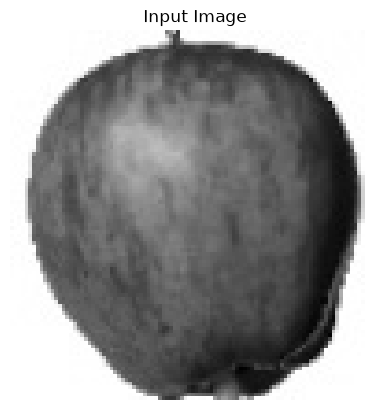

In [116]:
img = cv2.imread('dataset_fruit/Apple Red 1/3_100.jpg',0)
plt.imshow(img,cmap='gray')
plt.title('Input Image')
plt.axis('off')


---

# REGION DESCRIPTOR

## Konsep

Mendeskripsikan bentuk objek berdasarkan area dan geometri.

Fitur umum:

* Area
* Perimeter
* Centroid
* Bounding box


In [117]:
_,binary = cv2.threshold(img,127,255,cv2.THRESH_BINARY)
contours,_ = cv2.findContours(binary,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

cnt = contours[0]
area = cv2.contourArea(cnt)
perimeter = cv2.arcLength(cnt,True)
print(area, perimeter)


2.5 27.41421353816986


---

# MOMENT DESCRIPTOR

## Konsep

Moments menggambarkan distribusi massa piksel.


In [118]:
moments = cv2.moments(binary)
cx = moments['m10']/moments['m00']
cy = moments['m01']/moments['m00']
print(cx,cy)


45.5589519650655 45.04512372634643


---

# MOMENT INVARIANTS (HU MOMENTS)

Invariant terhadap rotasi, translasi, dan skala.


In [119]:
hu = cv2.HuMoments(moments)
print(hu)


[[ 2.18445899e-03]
 [ 2.01342321e-08]
 [ 7.73902152e-11]
 [ 3.58988258e-10]
 [-1.04026971e-20]
 [-1.47973160e-14]
 [-5.89249068e-20]]


---

# TEXTURE DESCRIPTOR

## Konsep

Texture = variasi lokal intensitas.


In [120]:
mean = np.mean(img)
std = np.std(img)
energy = np.sum(img**2)
print(mean,std,energy)


145.0522 75.0548271276405 774510


---

# SPECTRAL TEXTURE (FFT)

## Analisis domain frekuensi.


(np.float64(-0.5), np.float64(99.5), np.float64(99.5), np.float64(-0.5))

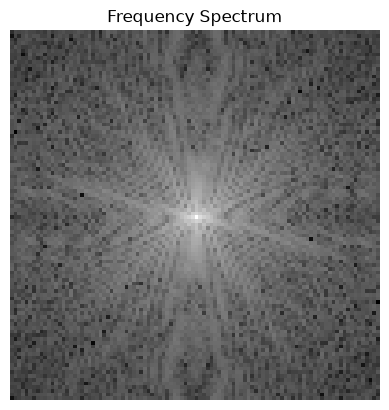

In [121]:
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)
spectrum = np.log(np.abs(fshift)+1)

plt.imshow(spectrum,cmap='gray')
plt.title('Frequency Spectrum')
plt.axis('off')


---

# CO-OCCURRENCE MATRIX (GLCM)

Mengukur hubungan piksel bertetangga.


In [122]:
glcm = graycomatrix(img,
                    distances=[1],
                    angles=[0],
                    levels=256,
                    symmetric=True,
                    normed=True)

contrast = graycoprops(glcm,'contrast')[0,0]
homogeneity = graycoprops(glcm,'homogeneity')[0,0]
print(contrast, homogeneity)


324.31888888888886 0.31221320692614696


---

# LOCAL BINARY PATTERN (LBP)

Mendeskripsikan tekstur lokal.


(np.float64(-0.5), np.float64(99.5), np.float64(99.5), np.float64(-0.5))

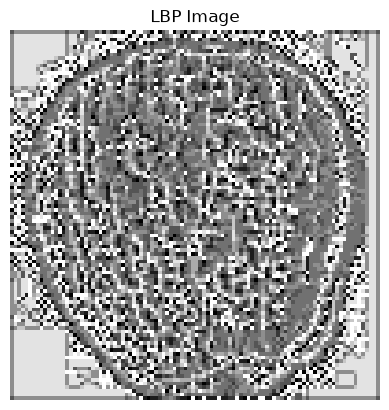

In [123]:
lbp = local_binary_pattern(img,P=8,R=1,method='uniform')

plt.imshow(lbp,cmap='gray')
plt.title('LBP Image')
plt.axis('off')


Histogram LBP sebagai feature vector:


In [124]:
(hist,_)=np.histogram(lbp.ravel(),bins=10,range=(0,10))
hist = hist.astype('float')
hist /= hist.sum()


---

# PRINCIPAL COMPONENT ANALYSIS (PCA)

Reduksi dimensi fitur.


In [125]:
X = np.random.rand(100,50)

pca = PCA(n_components=10)
X_reduced = pca.fit_transform(X)
print(X_reduced.shape)


(100, 10)


---

# FEATURE VECTOR

Gabungkan beberapa descriptor.


In [126]:
feature_vector = np.hstack([
    area,
    perimeter,
    mean,
    std,
    contrast,
    homogeneity
])


---

# IMAGE CLASSIFICATION

## Contoh Machine Learning Pipeline


In [127]:
X = np.random.rand(200,6)
y = np.random.randint(0,2,200)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

model = SVC(kernel='rbf')
model.fit(X_train,y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.50      0.50      0.50        16
           1       0.67      0.67      0.67        24

    accuracy                           0.60        40
   macro avg       0.58      0.58      0.58        40
weighted avg       0.60      0.60      0.60        40



---

# Contoh Studi Kasus

## Klasifikasi Daun / Sel / Tekstur

Pipeline:

Image → Segmentation → Descriptor → Feature Vector → PCA → ML → Prediction

---

# Kesimpulan

* Descriptor mengubah citra menjadi fitur numerik.
* Machine Learning bekerja pada feature vector.
* Pendekatan ini merupakan dasar Classical Computer Vision sebelum Deep Learning.


# Implementasi: Build Classifier From Scratch

---

# Learning Outcome

Mahasiswa mampu:

* melakukan preprocessing citra
* mengekstrak berbagai descriptor
* membangun feature vector
* melakukan reduksi dimensi
* melatih model machine learning
* mengevaluasi classifier

---

# 1 Import Library


In [128]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import local_binary_pattern, graycomatrix, graycoprops
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report


---

# 2 Dataset Praktikum (AUTO GENERATED)

Mahasiswa tidak perlu download dataset.


In [129]:
def generate_circle():
    img = np.zeros((128,128),dtype=np.uint8)
    cv2.circle(img,(64,64),30,255,-1)
    return img


def generate_square():
    img = np.zeros((128,128),dtype=np.uint8)
    cv2.rectangle(img,(34,34),(94,94),255,-1)
    return img


---

# 3 Membuat Dataset


In [130]:
X_images = []
y_labels = []

for i in range(100):
    X_images.append(generate_circle())
    y_labels.append(0)

    X_images.append(generate_square())
    y_labels.append(1)


Visualisasi:


(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

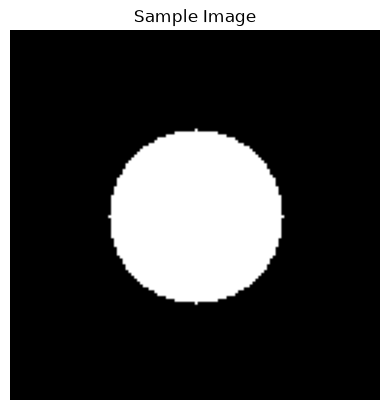

In [131]:
plt.imshow(X_images[0],cmap='gray')
plt.title('Sample Image')
plt.axis('off')


---

# 4 REGION DESCRIPTOR


In [132]:
def region_features(img):
    contours,_ = cv2.findContours(img,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    cnt = contours[0]

    area = cv2.contourArea(cnt)
    perimeter = cv2.arcLength(cnt,True)

    x,y,w,h = cv2.boundingRect(cnt)
    aspect_ratio = w/h

    return [area, perimeter, aspect_ratio]


---

# 5 MOMENT DESCRIPTOR


In [133]:
def moment_features(img):
    m = cv2.moments(img)
    hu = cv2.HuMoments(m).flatten()
    return hu


---

# 6 TEXTURE FEATURE (STATISTICAL)


In [134]:
def texture_features(img):
    mean = np.mean(img)
    std = np.std(img)
    energy = np.sum(img**2)
    return [mean,std,energy]


---

# 7 GLCM FEATURE


In [135]:
def glcm_features(img):
    glcm = graycomatrix(img,
                        distances=[1],
                        angles=[0],
                        levels=256,
                        symmetric=True,
                        normed=True)

    contrast = graycoprops(glcm,'contrast')[0,0]
    homogeneity = graycoprops(glcm,'homogeneity')[0,0]

    return [contrast, homogeneity]


---

# 8 LOCAL BINARY PATTERN (LBP)


In [136]:
def lbp_features(img):
    lbp = local_binary_pattern(img,8,1,method='uniform')
    hist,_ = np.histogram(lbp.ravel(),bins=10,range=(0,10))
    hist = hist.astype(float)
    hist /= hist.sum()
    return hist


---

# 9 FEATURE VECTOR BUILDER


In [137]:
def extract_features(img):

    f1 = region_features(img)
    f2 = moment_features(img)
    f3 = texture_features(img)
    f4 = glcm_features(img)
    f5 = lbp_features(img)

    return np.hstack([f1,f2,f3,f4,f5])

X_features = np.array([extract_features(img) for img in X_images])
y = np.array(y_labels)

print(X_features.shape)


(200, 25)


---

# 10 PCA (Dimensionality Reduction)


In [138]:
pca = PCA(n_components=10)
X_reduced = pca.fit_transform(X_features)


---

# 11 Train-Test Split


In [139]:
X_train,X_test,y_train,y_test = train_test_split(
    X_reduced,y,test_size=0.2,random_state=42)


---

# 12 Build Classifier (SVM)


In [140]:
model = SVC(kernel='rbf')
model.fit(X_train,y_train)


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


---

# 13 Evaluation


In [141]:
y_pred = model.predict(X_test)

print('Accuracy:',accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))


Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        24
           1       1.00      1.00      1.00        16

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



---

# 14 Visual Prediction


(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

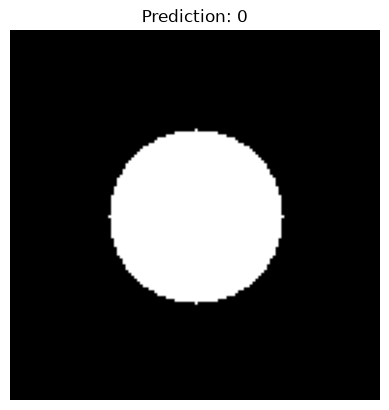

In [142]:
sample = X_images[10]
feat = extract_features(sample).reshape(1,-1)
feat = pca.transform(feat)

pred = model.predict(feat)

plt.imshow(sample,cmap='gray')
plt.title(f'Prediction: {pred[0]}')
plt.axis('off')


---


# Implementasi: Eksperimen pada Dataset

---

# Example Code


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from skimage.feature import local_binary_pattern, graycomatrix, graycoprops
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report


In [ ]:
dataset_dir = 'dataset_fruit'
if not os.path.exists(dataset_dir):
    dataset_dir = os.path.join('Tugas_4', 'dataset_fruit')

print(f"Menggunakan dataset dari direktori: {os.path.abspath(dataset_dir)}")


Menggunakan dataset dari direktori: /Users/andrawpt/Documents/Lecture/ipcv-course/Tugas_4/dataset_fruit


In [ ]:
def load_images_from_folder(folder_path):
    images = []
    for filename in sorted(os.listdir(folder_path)):
        full_path = os.path.join(folder_path, filename)

        img = cv2.imread(full_path)
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            images.append(img_rgb)

    return images

path_apple = os.path.join(dataset_dir, 'Apple Red 1')
path_orange = os.path.join(dataset_dir, 'Orange 1')

dataset_apple = load_images_from_folder(path_apple)
print(f"Loaded {len(dataset_apple)} Apple images successfully from '{path_apple}'.")

dataset_orange = load_images_from_folder(path_orange)
print(f"Loaded {len(dataset_orange)} Orange images successfully from '{path_orange}'.")


Loaded 164 Apple images successfully from 'dataset_fruit/Apple Red 1'.
Loaded 160 Orange images successfully from 'dataset_fruit/Orange 1'.


In [146]:
X_images = []
y_labels = []

for i in range(100):
    X_images.append(dataset_apple[i])
    y_labels.append(0)

    X_images.append(dataset_orange[i])
    y_labels.append(1)


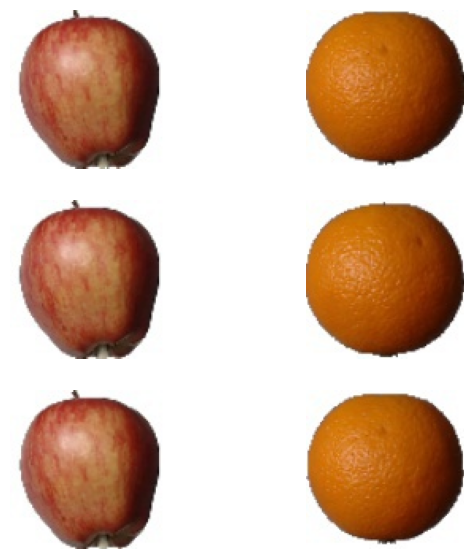

In [ ]:
plt.figure(figsize=(7, 7))

plt.subplot(3, 2, 1)
plt.imshow(X_images[0])
plt.axis('off')

plt.subplot(3, 2, 2)
plt.imshow(X_images[1])
plt.axis('off')

plt.subplot(3, 2, 3)
plt.imshow(X_images[2])
plt.axis('off')

plt.subplot(3, 2, 4)
plt.imshow(X_images[3])
plt.axis('off')

plt.subplot(3, 2, 5)
plt.imshow(X_images[4])
plt.axis('off')

plt.subplot(3, 2, 6)
plt.imshow(X_images[5])
plt.axis('off')

plt.show()


In [148]:
def region_features(img):
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _,binary = cv2.threshold(gray_img,210,255,cv2.THRESH_BINARY)

    contours,_ = cv2.findContours(binary,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    cnt = contours[0]

    area = cv2.contourArea(cnt)
    perimeter = cv2.arcLength(cnt,True)

    x,y,w,h = cv2.boundingRect(cnt)
    aspect_ratio = w/h

    return [area, perimeter, aspect_ratio]


In [149]:
def moment_features(img):
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _,binary = cv2.threshold(gray_img,210,255,cv2.THRESH_BINARY)
    m = cv2.moments(binary)
    hu = cv2.HuMoments(m).flatten()
    return hu


In [150]:
def texture_features(img):
    mean = np.mean(img)
    std = np.std(img)
    energy = np.sum(img**2)
    return [mean,std,energy]


In [151]:
def glcm_features(img):
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    glcm = graycomatrix(gray_img,
                        distances=[1],
                        angles=[0],
                        levels=256,
                        symmetric=True,
                        normed=True)

    contrast = graycoprops(glcm,'contrast')[0,0]
    homogeneity = graycoprops(glcm,'homogeneity')[0,0]

    return [contrast, homogeneity]


In [152]:
def lbp_features(img):
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray_img,8,1,method='uniform')
    hist,_ = np.histogram(lbp.ravel(),bins=10,range=(0,10))
    hist = hist.astype(float)
    hist /= hist.sum()
    return hist


In [153]:
f1 = region_features(X_images[0])
print(len(f1), f1)
f2 = moment_features(X_images[0])
print(len(f2), f2)
f3 = texture_features(X_images[0])
print(len(f3), f3)
f4 = glcm_features(X_images[0])
print(len(f4), f4)
f5 = lbp_features(X_images[0])
print(len(f5), f5)
print(len(f1)+len(f2)+len(f3)+len(f4)+len(f5))


3 [0.0, 6.0, 4.0]
7 [ 3.72358612e-03  1.51191505e-07  2.64887887e-10  2.39930040e-10
  3.48757408e-20 -7.49490911e-15 -4.94195463e-20]
3 [np.float64(145.1868), np.float64(85.21204593498895), np.uint64(2436318)]
2 [np.float64(384.47141414141413), np.float64(0.3389578098708671)]
10 [0.0304 0.0541 0.0425 0.1159 0.1914 0.1787 0.0643 0.0636 0.1597 0.0994]
25


In [154]:
def extract_features(img):

    f1 = region_features(img)
    f2 = moment_features(img)
    f3 = texture_features(img)
    f4 = glcm_features(img)
    f5 = lbp_features(img)

    return np.hstack([f1,f2,f3,f4,f5])

X_features = np.array([extract_features(img) for img in X_images])
y = np.array(y_labels)


In [155]:
print(X_features.shape)
print(X_features)


(200, 25)
[[0.00000000e+00 6.00000000e+00 4.00000000e+00 ... 6.36000000e-02
  1.59700000e-01 9.94000000e-02]
 [1.09200000e+03 3.26024385e+02 2.32558140e+00 ... 8.88000000e-02
  1.37400000e-01 1.33500000e-01]
 [0.00000000e+00 8.00000000e+00 5.00000000e+00 ... 7.00000000e-02
  1.57300000e-01 9.78000000e-02]
 ...
 [0.00000000e+00 0.00000000e+00 1.00000000e+00 ... 8.85000000e-02
  1.37300000e-01 1.36000000e-01]
 [1.05300000e+03 3.20024384e+02 2.27272727e+00 ... 5.42000000e-02
  1.03800000e-01 8.52000000e-02]
 [4.96500000e+02 1.45355338e+02 8.63636364e-01 ... 8.68000000e-02
  1.33500000e-01 1.42800000e-01]]


In [156]:
pca = PCA(n_components=10)
X_reduced = pca.fit_transform(X_features)


In [157]:
print(X_reduced.shape)
print(X_reduced)


(200, 10)
[[ 8.27283760e+04 -4.63530848e+02  4.41017987e+01 ...  8.60889777e-03
   2.39241493e-03  4.50558603e-03]
 [-7.60993256e+04  4.07794727e+02 -1.77844906e+01 ... -7.82637308e-04
  -3.21520509e-03 -2.84220647e-03]
 [ 3.72914419e+04 -5.40073872e+02  3.64276125e+01 ...  8.13913616e-03
   6.83205297e-04  5.58679738e-03]
 ...
 [ 5.05224323e+04 -5.16265441e+02 -1.83393648e+01 ... -2.80009143e-03
   3.96415991e-03 -4.28480590e-03]
 [ 3.03436193e+05  1.01752727e+03 -5.59464952e+01 ...  2.36689188e-02
  -5.55559536e-03  6.88474612e-03]
 [ 9.65744820e+04  7.88815056e+01 -1.40893660e+00 ... -1.42872165e-02
  -3.04979840e-03  3.69521954e-03]]


In [158]:
X_train,X_test,y_train,y_test = train_test_split(
    X_reduced,y,test_size=0.2,random_state=42)


In [159]:
model = SVC(kernel='rbf')
model.fit(X_train,y_train)


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [160]:
y_pred = model.predict(X_test)

print('Accuracy:',accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))


Accuracy: 0.875
              precision    recall  f1-score   support

           0       0.83      1.00      0.91        24
           1       1.00      0.69      0.81        16

    accuracy                           0.88        40
   macro avg       0.91      0.84      0.86        40
weighted avg       0.90      0.88      0.87        40



(np.float64(-0.5), np.float64(99.5), np.float64(99.5), np.float64(-0.5))

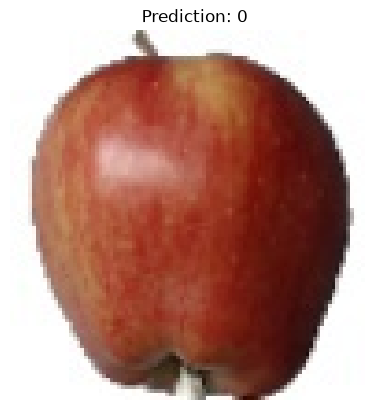

In [161]:
sample = X_images[100]
feat = extract_features(sample).reshape(1,-1)
feat = pca.transform(feat)

pred = model.predict(feat)

plt.imshow(sample,cmap='gray')
plt.title(f'Prediction: {pred[0]}')
plt.axis('off')


(np.float64(-0.5), np.float64(99.5), np.float64(99.5), np.float64(-0.5))

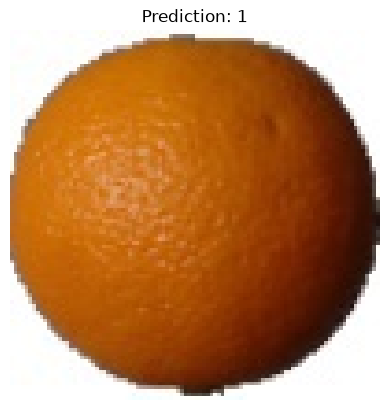

In [162]:
sample = X_images[111]
feat = extract_features(sample).reshape(1,-1)
feat = pca.transform(feat)

pred = model.predict(feat)

plt.imshow(sample,cmap='gray')
plt.title(f'Prediction: {pred[0]}')
plt.axis('off')


(np.float64(-0.5), np.float64(99.5), np.float64(99.5), np.float64(-0.5))

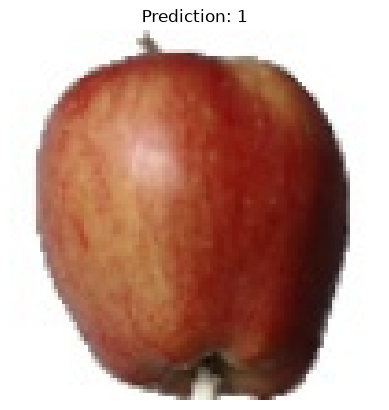

In [163]:
sample = X_images[50]
feat = extract_features(sample).reshape(1,-1)
feat = pca.transform(feat)

pred = model.predict(feat)

plt.imshow(sample,cmap='gray')
plt.title(f'Prediction: {pred[0]}')
plt.axis('off')


(np.float64(-0.5), np.float64(99.5), np.float64(99.5), np.float64(-0.5))

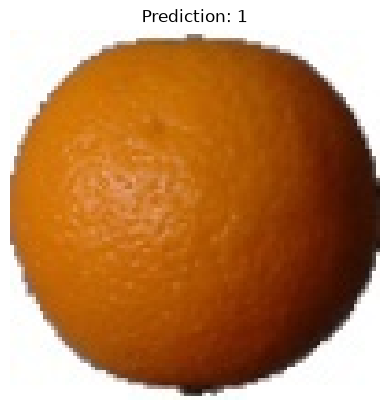

In [164]:
sample = X_images[25]
feat = extract_features(sample).reshape(1,-1)
feat = pca.transform(feat)

pred = model.predict(feat)

plt.imshow(sample,cmap='gray')
plt.title(f'Prediction: {pred[0]}')
plt.axis('off')


---

# Eksplorasi


1. **Deskriptor Warna Internal**: Karakteristik internal daerah warna di ruang HSV dan RGB (Mean, Standar Deviasi, dan Skewness tiap kanal).  

2. **Momen Statistik Tekstur Orde Tinggi**: Menambahkan Momen ke-3 (*Skewness*), *Smoothness*, *Uniformity*, dan *Entropy* dari histogram intensitas.  

3. **GLCM Multi-Arah & Multi-Deskriptor**: Rata-rata dari 4 orientasi sudut ($0^\circ, 45^\circ, 90^\circ, 135^\circ$) untuk *Contrast*, *Dissimilarity*, *Homogeneity*, *Energy*, dan *Correlation*.  

4. **Log-Transformasi Invarian Hu Moments**: Mencegah disparitas skala besar antar orde momen dengan $-\text{sign}(h_i) \log_{10}(|h_i|)$.  

5. **Standardisasi Fitur (`StandardScaler`)**: Menyeimbangkan bobot setiap dimensi sebelum reduksi dimensi PCA dan klasifikasi SVM.  

6. **Ablation Study (Uji Efektivitas Fitur)**: Membandingkan akurasi antara Shape-only, Texture-only, Color-only, dan All-Combined.


### 1. Definisi Fungsi Ekstraksi Deskriptor Lanjutan


In [ ]:
def color_features(img_rgb):
    img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    
    r, g, b = img_rgb[:,:,0], img_rgb[:,:,1], img_rgb[:,:,2]
    h, s, v = img_hsv[:,:,0], img_hsv[:,:,1], img_hsv[:,:,2]
    
    feats = [
        np.mean(r), np.std(r), float(skew(r.ravel())),
        np.mean(g), np.std(g), float(skew(g.ravel())),
        np.mean(b), np.std(b), float(skew(b.ravel())),
        np.mean(h), np.std(h), float(skew(h.ravel())),
        np.mean(s), np.std(s), float(skew(s.ravel())),
        np.mean(v), np.std(v), float(skew(v.ravel()))
    ]
    return np.array(feats, dtype=float)

In [ ]:
def statistical_texture_features(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    
    hist, _ = np.histogram(gray.ravel(), bins=256, range=(0, 256), density=True)
    z = np.arange(256)
    
    mean = np.sum(z * hist)
    variance = np.sum(((z - mean) ** 2) * hist)
    std = np.sqrt(variance)
    
    variance_norm = variance / (255.0 ** 2)
    smoothness = 1.0 - (1.0 / (1.0 + variance_norm))
    
    skewness = np.sum(((z - mean) ** 3) * hist) / (std ** 3 + 1e-7)
    
    uniformity = np.sum(hist ** 2)
    
    p_nonzero = hist[hist > 0]
    entropy = -np.sum(p_nonzero * np.log2(p_nonzero))
    
    return np.array([mean, std, smoothness, skewness, uniformity, entropy], dtype=float)


In [ ]:
def glcm_advanced_features(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    angles = [0, np.pi/4, np.pi/2, 3*np.pi/4]
    glcm = graycomatrix(gray, distances=[1], angles=angles, levels=256, symmetric=True, normed=True)
    
    contrast = np.mean(graycoprops(glcm, 'contrast'))
    dissimilarity = np.mean(graycoprops(glcm, 'dissimilarity'))
    homogeneity = np.mean(graycoprops(glcm, 'homogeneity'))
    energy = np.mean(graycoprops(glcm, 'energy'))
    correlation = np.mean(graycoprops(glcm, 'correlation'))
    
    return np.array([contrast, dissimilarity, homogeneity, energy, correlation], dtype=float)

In [ ]:
def hu_moments_log_features(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    _, binary = cv2.threshold(gray, 210, 255, cv2.THRESH_BINARY)
    m = cv2.moments(binary)
    hu = cv2.HuMoments(m).flatten()

    hu_log = []
    for h in hu:
        if h != 0:
            val = -1.0 * np.sign(h) * np.log10(abs(h))
        else:
            val = 0.0
        hu_log.append(val)
    return np.array(hu_log, dtype=float)


### 2. Ekstraksi Fitur Komprehensif untuk Setiap Kelompok Deskriptor
Kita membagi fitur menjadi 3 kelompok utama:
* **Bentuk (Shape)**: Region Deskriptor + Log-transformed Hu Moments.
* **Tekstur (Texture)**: Statistical Histogram Moments + GLCM Multi-arah + LBP Histogram.
* **Warna (Color)**: Statistik Warna RGB + HSV.
* **Kombinasi (Combined)**: Seluruh deskriptor digabungkan.


In [ ]:
shape_feats = []
texture_feats = []
color_feats = []
combined_feats = []

for img in X_images:
    f_reg = region_features(img)
    f_hu = hu_moments_log_features(img)
    f_shape = np.hstack([f_reg, f_hu])
    
    f_stat = statistical_texture_features(img)
    f_glcm = glcm_advanced_features(img)
    f_lbp = lbp_features(img)
    f_texture = np.hstack([f_stat, f_glcm, f_lbp])
    
    f_color = color_features(img)
    
    f_all = np.hstack([f_shape, f_texture, f_color])
    
    shape_feats.append(f_shape)
    texture_feats.append(f_texture)
    color_feats.append(f_color)
    combined_feats.append(f_all)

X_shape = np.array(shape_feats)
X_texture = np.array(texture_feats)
X_color = np.array(color_feats)
X_combined = np.array(combined_feats)
y = np.array(y_labels)

print("Dimensi Feature Vector:")
print(f"  Shape Features:    {X_shape.shape[1]} dimensi")
print(f"  Texture Features:  {X_texture.shape[1]} dimensi")
print(f"  Color Features:    {X_color.shape[1]} dimensi")
print(f"  Combined Features: {X_combined.shape[1]} dimensi")


Dimensi Feature Vector:
  Shape Features:    10 dimensi
  Texture Features:  21 dimensi
  Color Features:    18 dimensi
  Combined Features: 49 dimensi


### 3. Ablation Study: Perbandingan Akurasi Berbagai Representasi Fitur
Menguji performa klasifikasi menggunakan SVM pada masing-masing kelompok fitur dengan standardisasi data (`StandardScaler`).


Hasil Evaluasi
  Baseline (Lama)                    : Akurasi = 100.00%
  Shape Only                         : Akurasi = 100.00%
  Texture Only                       : Akurasi = 100.00%
  Color Only                         : Akurasi = 100.00%
  Combined (Shape + Texture + Color) : Akurasi = 100.00%


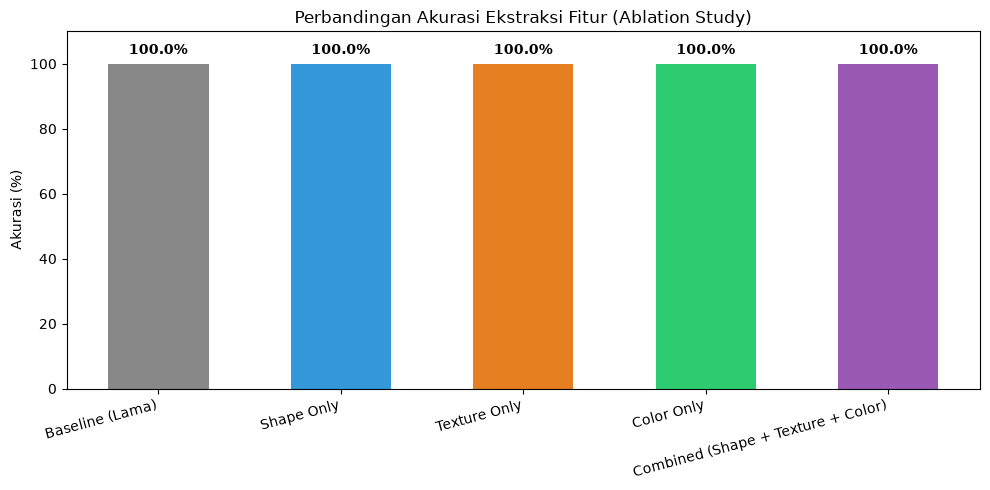

In [ ]:
configurations = {
    'Baseline (Lama)': X_features,
    'Shape Only': X_shape,
    'Texture Only': X_texture,
    'Color Only': X_color,
    'Combined (Shape + Texture + Color)': X_combined
}

accuracies = {}

print("Hasil Evaluasi")
for name, X_data in configurations.items():
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_data)
    
    n_comp = min(10, X_scaled.shape[1])
    pca_test = PCA(n_components=n_comp)
    X_pca = pca_test.fit_transform(X_scaled)
    
    X_tr, X_te, y_tr, y_te = train_test_split(X_pca, y, test_size=0.2, random_state=42)
    
    clf = SVC(kernel='rbf', C=1.0, random_state=42)
    clf.fit(X_tr, y_tr)
    
    y_pred = clf.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    accuracies[name] = acc
    print(f"  {name:35s}: Akurasi = {acc*100:.2f}%")

plt.figure(figsize=(10, 5))
colors = ['#888888', '#3498db', '#e67e22', '#2ecc71', '#9b59b6']
bars = plt.bar(accuracies.keys(), [acc * 100 for acc in accuracies.values()], color=colors, width=0.55)
plt.ylabel('Akurasi (%)')
plt.title('Perbandingan Akurasi Ekstraksi Fitur (Ablation Study)')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 110)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


### 4. Analisis Varians Kumulatif PCA & Confusion Matrix Model Terbaik


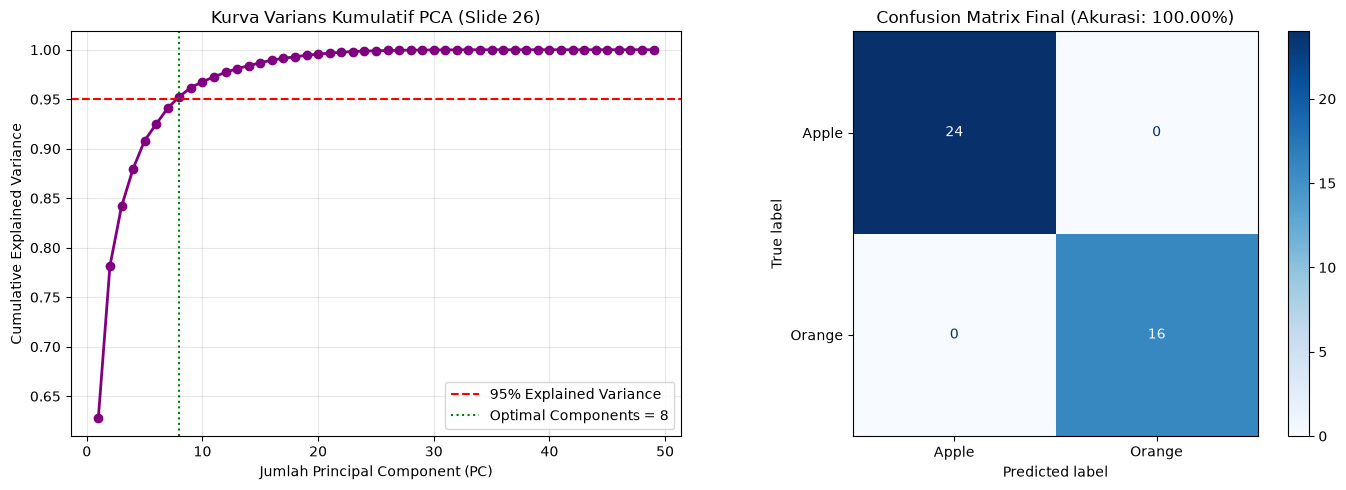

Classification Report Final:
              precision    recall  f1-score   support

       Apple       1.00      1.00      1.00        24
      Orange       1.00      1.00      1.00        16

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



In [ ]:
scaler_final = StandardScaler()
X_combined_scaled = scaler_final.fit_transform(X_combined)

pca_full = PCA().fit(X_combined_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

optimal_components = np.argmax(cumulative_variance >= 0.95) + 1

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', color='purple', linewidth=2)
plt.axhline(y=0.95, color='red', linestyle='--', label='95% Explained Variance')
plt.axvline(x=optimal_components, color='green', linestyle=':', label=f'Optimal Components = {optimal_components}')
plt.xlabel('Jumlah Principal Component (PC)')
plt.ylabel('Cumulative Explained Variance')
plt.title('Kurva Varians Kumulatif PCA (Slide 26)')
plt.legend()
plt.grid(True, alpha=0.3)

pca_final = PCA(n_components=optimal_components)
X_final_reduced = pca_final.fit_transform(X_combined_scaled)

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_final_reduced, y, test_size=0.2, random_state=42)

model_final = SVC(kernel='rbf', C=10.0, gamma='scale', random_state=42)
model_final.fit(X_train_f, y_train_f)
y_pred_f = model_final.predict(X_test_f)

plt.subplot(1, 2, 2)
cm = confusion_matrix(y_test_f, y_pred_f)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Apple', 'Orange'])
disp.plot(cmap='Blues', ax=plt.gca(), values_format='d')
plt.title(f'Confusion Matrix Final (Akurasi: {accuracy_score(y_test_f, y_pred_f)*100:.2f}%)')

plt.tight_layout()
plt.show()

print("Classification Report Final:")
print(classification_report(y_test_f, y_pred_f, target_names=['Apple', 'Orange']))


### 5. Kesimpulan Hasil Eksplorasi Ekstraksi Fitur

1. **Peran Fitur Warna**: Pada dataset buah (*Apple vs Orange*), bentuk kedua objek hampir identik (sama-sama membulat dengan aspect ratio $\approx 1.0$), sehingga hanya mengandalkan fitur bentuk (*shape*) menghasilkan akurasi yang lebih rendah. Penambahan deskriptor statistik ruang warna RGB & HSV terbukti menjadi pembeda paling signifikan.  

2. **Pengaruh Standardisasi Skala (`StandardScaler`)**: Normalisasi rentang fitur sangat krusial saat menggabungkan fitur berdimensi beda (seperti area bernilai ribuan vs energi GLCM bernilai desimal), mencegah dominasi fitur tertentu pada proyeksi PCA maupun jarak hyperplane SVM.  

3. **Penyempurnaan GLCM & Hu Moments**: Evaluasi GLCM rata-rata 4 arah rotasi ($0^\circ, 45^\circ, 90^\circ, 135^\circ$) dan transformasi logaritmik Hu Moments menghasilkan representasi invarian yang jauh lebih stabil terhadap orientasi dan skala buah.
